# Daily residual and input diagnostics

Compare the native hybrid ensembles with and without dew point. The inputs shown alongside the residuals are aligned to the mortality dates.

[Original analysis notebook](https://github.com/ClimSocAna/sari-weather-mortality/blob/4402a80d3e490ad7964a3be12597043761bebda1/notebooks/05_daily_residual_diagnostics.ipynb).

The primary hybrid uses 50 members. Comparison ensembles use all of their available members.

In [ ]:
from importlib.util import module_from_spec, spec_from_file_location
from pathlib import Path
import sys

cwd = Path.cwd()
repo = next(
    (
        path for path in (cwd, *cwd.parents)
        if (path / "configs" / "training.example.yaml").is_file()
    ),
    None,
)
if repo is None:
    raise FileNotFoundError("Open the notebook from the sari-weather-mortality checkout.")

sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Load helpers from this checkout even if Jupyter cached another notebooks package.
utils_path = repo / "notebooks" / "utils.py"
spec = spec_from_file_location("sari_notebook_utils", utils_path)
notebook_utils = module_from_spec(spec)
spec.loader.exec_module(notebook_utils)

if not hasattr(notebook_utils, "weekly_surveillance"):
    raise ImportError(f"{utils_path} is missing weekly_surveillance. Update to commit d5351c3 or newer.")

daily_index = notebook_utils.daily_index
ensemble = notebook_utils.ensemble
national_daily = notebook_utils.national_daily
ANALYSIS_PERIOD = notebook_utils.ANALYSIS_PERIOD
DEVICE = notebook_utils.DEVICE
checkpoint_paths = notebook_utils.checkpoint_paths
weekly_surveillance = notebook_utils.weekly_surveillance

from sari_t.reference import relative_humidity_percent
from sari_t.inference import InferenceModel
from sari_t.run.checkpoint import load_checkpoint, load_run_config, restore_predictor

## Load models for inspection

Run the next cell to load member `000` for each setup into memory. Inspect `model` for the hybrid predictor or `models[setup]` for another predictor. Set `inspection_member` to another available member index to inspect its weights. The analysis cells evaluate all available members in a separate inference workspace.

In [ ]:
inspection_member = 0
setups = ['default', 'tas_only']
checkpoints = {setup: checkpoint_paths(setup) for setup in setups}
models = {
    setup: restore_predictor(load_checkpoint(paths[inspection_member]), device="cpu").eval()
    for setup, paths in checkpoints.items()
}
model = models["default"]
model

MortalityPredictor(
  (effect_model): ExponentialMortalityModel(
    (batch_norm): LazyBatchNorm1d(0, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv1): LazyConv1d(0, 128, kernel_size=(9,), stride=(1,))
    (fc): LinearPos(in_features=128, out_features=30, bias=True)
    (sari_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
    (covid_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
  )
)

## Reconstruct daily mortality and align the inputs

In [ ]:
def summarize(model, result):
    daily = national_daily(model, result)
    count = daily["Predicted"].numel()
    inputs = model.data.model_inputs
    tas = inputs.temperature[:, 0, -count:]
    tdew = inputs.temperature[:, 1, -count:]
    daily["Temperature (°C)"] = tas.mean(dim=0)
    daily["Relative humidity (%)"] = relative_humidity_percent(tas, tdew).mean(dim=0)
    return daily

summaries = {"default": summarize, "tas_only": national_daily}

estimates_by_setup = {}
for setup, summarize_member in summaries.items():
    paths = checkpoints[setup]
    inputs = load_run_config(paths[0].parents[1] / "config.yaml").data_config
    inference_model = InferenceModel.from_checkpoint(
        paths[0], data_config=inputs, period=ANALYSIS_PERIOD, device=DEVICE,
    )
    estimates_by_setup[setup] = ensemble(inference_model, paths, summarize_member)
    del inference_model

hybrid = estimates_by_setup["default"]
tas_only = estimates_by_setup["tas_only"]
if not hybrid["Observed"].equal(tas_only["Observed"]):
    raise ValueError("The ensembles must use the same observed mortality labels.")

dates = daily_index()
val = hybrid["Observed"]
tr = {"baseline_adaptive": hybrid["Predicted"], "tas_only": tas_only["Predicted"]}
t_day = hybrid["Temperature (°C)"]
t_rh_day = hybrid["Relative humidity (%)"]
incidence = weekly_surveillance(dates)
covid = incidence["COVID-19"].fillna(0)
sari_incidence = torch.as_tensor((incidence["Gesamt"] - covid).to_numpy())
covid_incidence = torch.as_tensor(covid.to_numpy())

/local/job_26447960/ipykernel_2458106/4079578075.py:35: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  sari_incidence = torch.as_tensor((incidence["Gesamt"] - covid).to_numpy())


## Supplementary Figure 7: Residual comparison with and without dew point

The first diagnostic contrasts daily residuals from the two weather-input configurations and displays observed deaths below them. Persistent differences indicate periods where the humidity indicator changes reconstruction.

,Date,Residual without dew point,Residual with dew point,Underestimation reduced
0,2015-07-15,-29.019531,-21.421387,False
1,2020-06-08,-71.129883,-50.791992,False
2,2021-06-08,87.908936,61.292725,True


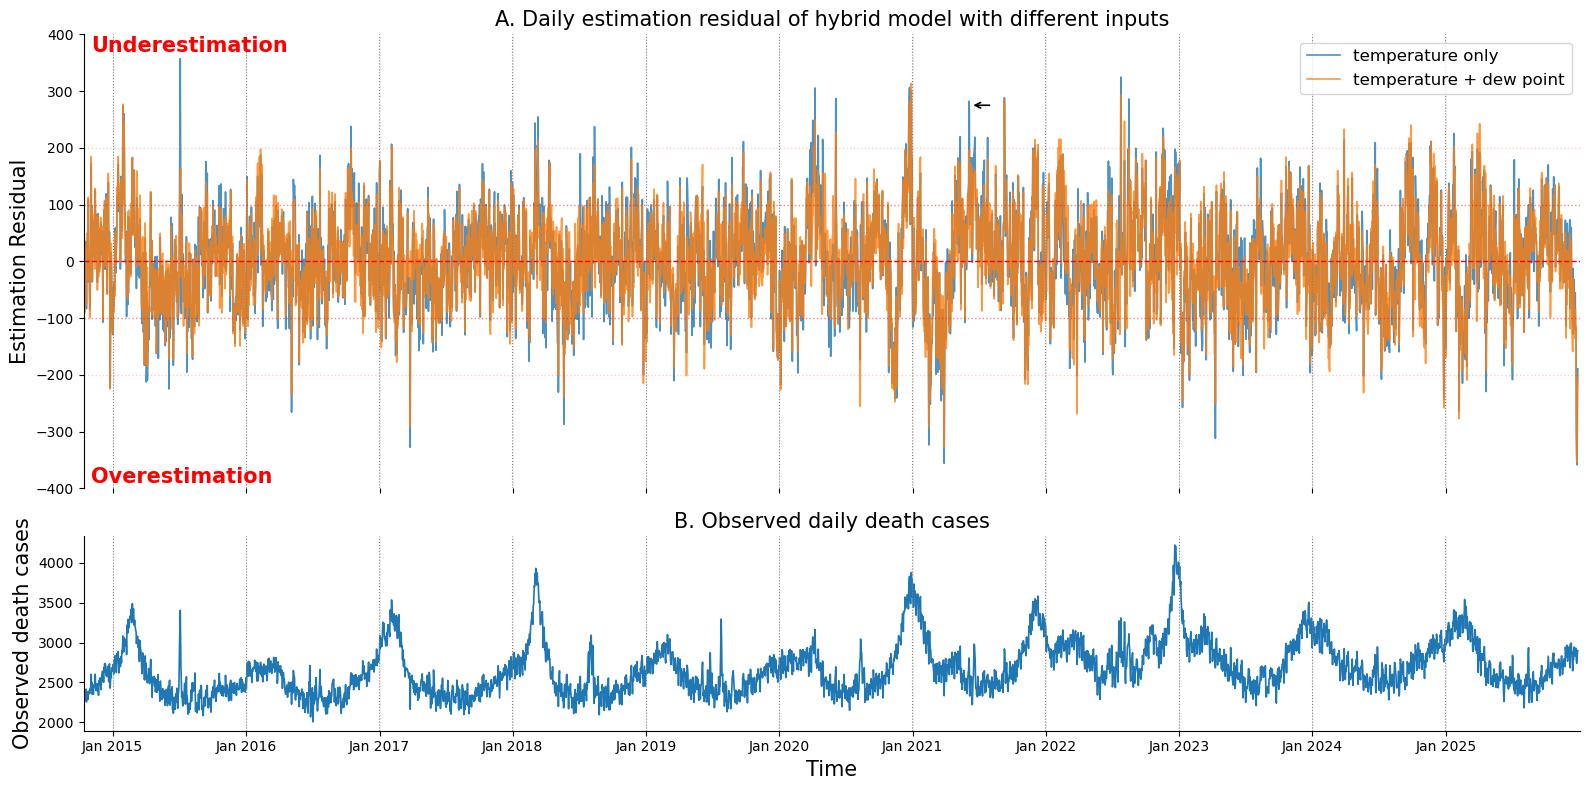

In [ ]:
days_cumulative = 80
ticks = []
for year in range(2015, 2026):
    ticks.append(days_cumulative)  # Store the start of each year
    # Add days based on whether it's a leap year
    days_in_year = 366 if (year % 4 == 0 and (year % 100 != 0 or year % 400 == 0)) else 365
    days_cumulative += days_in_year

# x range (assumes len(val) >= 3800 as in your code)
xmax = 4100
x = np.arange(xmax)

fig, axes = plt.subplots(2, 1, figsize=(16,8), sharex=True, gridspec_kw={'height_ratios': [7, 3]})

# Retain only original annotations supported by the revised residuals.
arrow_days = [275, 2065, 2430]
without_dew = (val - tr["tas_only"])[arrow_days].numpy()
with_dew = (val - tr["baseline_adaptive"])[arrow_days].numpy()
improved = (without_dew > 0) & (np.abs(with_dew) < without_dew)
display(pd.DataFrame({
    "Date": dates[arrow_days],
    "Residual without dew point": without_dew,
    "Residual with dew point": with_dew,
    "Underestimation reduced": improved,
}))
# --- Panel A: estimation error ---
ax = axes[0]
ax.plot((val - tr['tas_only'])[:xmax], lw=1.2, label='temperature only', alpha=0.8)
ax.plot((val - tr['baseline_adaptive'])[:xmax], lw=1.2, label='temperature + dew point', alpha=0.8)

# reference lines
ax.axhline(0, color='red', lw=1.0, ls='--')
for y, a in [(100, 0.5), (200, 0.2)]:
    ax.axhline(y,  color='red', lw=1, ls=':', alpha=a)
    ax.axhline(-y, color='red', lw=1, ls=':', alpha=a)

# seasonal separators
for j in range(11):
    ax.axvline(j*365 + 80, color='grey', lw=0.8, ls=':')

# region labels
ax.text(20, -0.95*400,  "Overestimation",  color='red', fontsize=15, va='center', ha='left', fontweight='semibold')
ax.text(20, 0.95*400,  "Underestimation", color='red', fontsize=15, va='center', ha='left', fontweight='semibold')

# style
ax.set_xlim(0, xmax)
ax.set_ylim(-400, 400)
ax.grid(True, axis='x', ls='--', lw=0.5, alpha=0.4)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_ylabel('Estimation Residual', fontsize=15)
ax.set_title('A. Daily estimation residual of hybrid model with different inputs', fontsize=15)
ax.legend(loc='upper right', fontsize=12)

if improved[0]:
    ax.annotate(
        "",
        xy=(275, 280), xycoords='data',
        xytext=(275 + 60, 280), textcoords='data',
        arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
    )

if improved[1]:
    ax.annotate(
        "",
        xy=(2065, 270), xycoords='data',
        xytext=(2065 + 60, 270), textcoords='data',
        arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
    )

if improved[2]:
    ax.annotate(
        "",
        xy=(2430, 275), xycoords='data',
        xytext=(2430 + 60, 275), textcoords='data',
        arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
    )

# --- Panel B: observed values (pure val) ---
ax2 = axes[1]
ax2.plot(val[:xmax], lw=1.2)
for j in range(11):
    ax2.axvline(j*365 + 80, color='grey', lw=0.8, ls=':')

ax2.grid(True, axis='x', ls='--', lw=0.5, alpha=0.4)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.set_ylabel('Observed death cases', fontsize=15)
ax2.set_title('B. Observed daily death cases', fontsize=15)

# shared x labels/ticks

ax2.set_xlabel('Time', fontsize=15)
axes[1].set_xticks(ticks)
axes[1].set_xticklabels([f"Jan {year}" for year in range(2015, 2026)])

plt.tight_layout()
# plt.savefig("comparison_tas_dew_point.png", dpi=300, bbox_inches='tight')
plt.show()

## Additional diagnostic: Residuals and respiratory-infection inputs

National non-COVID SARI and COVID-19-associated SARI incidence are aligned with hybrid-model residuals and temperature. This view supports visual checks for residual winter structure not captured by the fitted components.

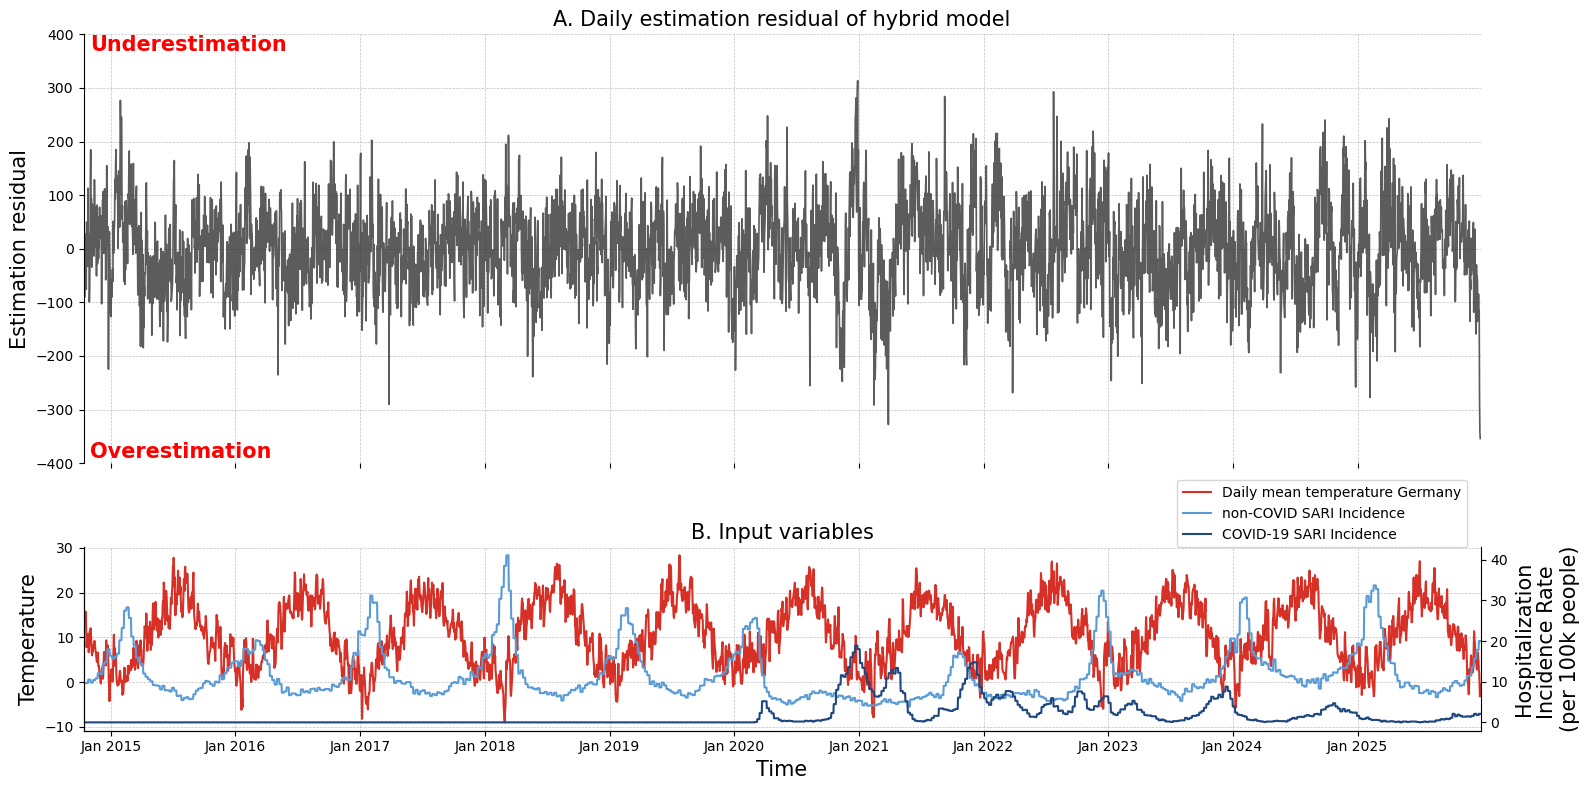

In [ ]:
from matplotlib.lines import Line2D

# x range (assumes len(val) >= 3731 as in your code)
xmax = 3731 + 362
x = np.arange(xmax)

fig, axes = plt.subplots(2, 1, figsize=(16,8), sharex=True, gridspec_kw={'height_ratios': [7, 3]})

# --- Panel A: estimation error ---
ax = axes[0]
ax.plot((val - tr['baseline_adaptive'])[:xmax], lw=1.2, label='residual', alpha=0.8, color='0.2')

# region labels
ax.text(20, -0.95*400,  "Overestimation",  color='red', fontsize=15, va='center', ha='left', fontweight='semibold')
ax.text(20, 0.95*400,  "Underestimation", color='red', fontsize=15, va='center', ha='left', fontweight='semibold')

# style
ax.set_xlim(0, xmax)
ax.set_ylim(-400, 400)
ax.grid(True, axis='both', ls='--', lw=0.5, alpha=0.8)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_ylabel('Estimation residual', fontsize=15)
ax.set_title('A. Daily estimation residual of hybrid model', fontsize=15)
# ax.legend(loc='upper right', fontsize=12)

# --- Panel B: observed values (pure val) ---
ax2 = axes[1]
ax2.plot(t_day, lw=1.5, color= "#D73027" )

ax_twin = ax2.twinx()
ax_twin.plot(sari_incidence.repeat_interleave(7)[:xmax], color="#5B9BD5", lw=1.5)
ax_twin.plot(covid_incidence.repeat_interleave(7)[:xmax], color='#1E4780', lw=1.5)
ax_twin.set_ylabel('Hospitalization\nIncidence Rate \n(per 100k people)', fontsize=15)

ax_twin.spines['top'].set_visible(False)


ax2.grid(True, axis='both', ls='--', lw=0.5, alpha=0.8)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.set_ylabel('Temperature', fontsize=15)
ax2.set_title('B. Input variables', fontsize=15)

# shared x labels/ticks

ax2.set_xlabel('Time', fontsize=15)
axes[1].set_xticks(ticks)
axes[1].set_xticklabels([f"Jan {year}" for year in range(2015, 2026)])

custom_lines = [
    Line2D([0], [0], color="#D73027", linestyle="-"),
    Line2D([0], [0], color="#5B9BD5", linestyle="-"),
    Line2D([0], [0], color="#1E4780", linestyle="-"),   # Men
]

legend_labels = [
    "Daily mean temperature Germany",
    "non-COVID SARI Incidence",
    "COVID-19 SARI Incidence",
]


# 线型 legend（Registered / Baseline）放在左上角第一幅图
ax2.legend(
    custom_lines,
    legend_labels,
    loc="upper right",
    fontsize=10,
    bbox_to_anchor=(0.995, 1.4),
)

plt.tight_layout()
# plt.savefig("residual_input.png", dpi=300, bbox_inches='tight')
plt.show()

## Additional diagnostic: Temperature and relative-humidity diagnostics

Dew-point temperature is converted to relative humidity to compare national mean weather conditions with mortality residuals. These panels are descriptive diagnostics and do not replace the controlled response analysis in the temperature-humidity notebook.

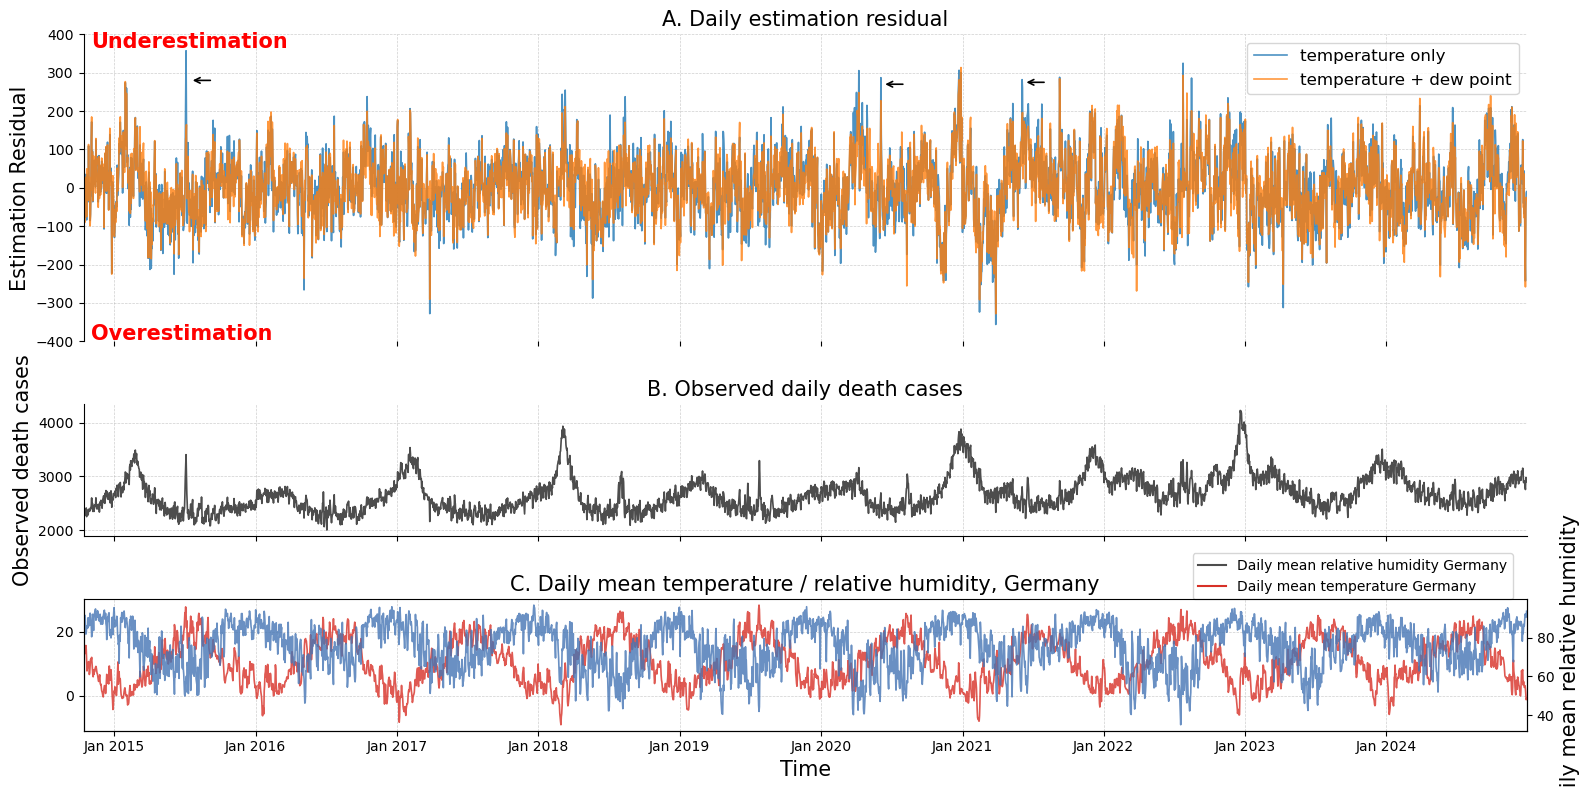

In [ ]:
import matplotlib.pyplot as plt
import numpy as np



# x range (assumes len(val) >= 3800 as in your code)
xmax = 3731
x = np.arange(xmax)

fig, axes = plt.subplots(3, 1, figsize=(16,8), sharex=True, gridspec_kw={'height_ratios': [7, 3, 3]})

# --- Panel A: estimation error ---
ax = axes[0]
ax.plot((val - tr['tas_only'])[:xmax], lw=1.2, label='temperature only', alpha=0.8)
ax.plot((val - tr['baseline_adaptive'])[:xmax], lw=1.2, label='temperature + dew point', alpha=0.8)

# region labels
ax.text(20, -0.95*400,  "Overestimation",  color='red', fontsize=15, va='center', ha='left', fontweight='semibold')
ax.text(20, 0.95*400,  "Underestimation", color='red', fontsize=15, va='center', ha='left', fontweight='semibold')

# style
ax.set_xlim(0, xmax)
ax.set_ylim(-400, 400)
ax.grid(True, axis='both', ls='--', lw=0.5, alpha=0.6)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_ylabel('Estimation Residual', fontsize=15)
ax.set_title('A. Daily estimation residual', fontsize=15)
ax.legend(loc='upper right', fontsize=12)

ax.annotate(
    "",
    xy=(275, 280), xycoords='data',
    xytext=(275 + 60, 280), textcoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

ax.annotate(
    "",
    xy=(2065, 270), xycoords='data',
    xytext=(2065 + 60, 270), textcoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

ax.annotate(
    "",
    xy=(2430, 275), xycoords='data',
    xytext=(2430 + 60, 275), textcoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

# --- Panel B: observed values (pure val) ---
ax2 = axes[1]
ax2.plot(val[:xmax], lw=1.2, color='0.3')


ax2.grid(True, axis='both', ls='--', lw=0.5, alpha=0.6)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.set_ylabel('Observed death cases', fontsize=15)
ax2.set_title('B. Observed daily death cases', fontsize=15)

ax3 = axes[2]
ax3.plot(t_day[:xmax], lw=1.2, color='#D73027', alpha=0.8)

ax_twin = ax3.twinx()
ax_twin.plot(t_rh_day[:xmax], lw=1.2, color='#4575B4', alpha=0.8)
ax_twin.set_ylabel('Daily mean relative humidity', fontsize=15)

ax3.grid(True, axis='both', ls='--', lw=0.5, alpha=0.6)
ax3.spines['top'].set_visible(False)
ax3.set_title('C. Daily mean temperature / relative humidity, Germany', fontsize=15)


axes[2].set_xlabel('Time', fontsize=15)
visible_ticks = [(tick, f"Jan {year}") for year, tick in enumerate(ticks, start=2015) if tick < xmax]
axes[2].set_xticks([tick for tick, _ in visible_ticks], [label for _, label in visible_ticks])

custom_lines = [
    Line2D([0], [0], color="0.3", linestyle="-"),
    Line2D([0], [0], color="#D73027", linestyle="-"),
]

legend_labels = [
    "Daily mean relative humidity Germany",
    "Daily mean temperature Germany",
]


# 线型 legend（Registered / Baseline）放在左上角第一幅图
axes[2].legend(
    custom_lines,
    legend_labels,
    loc="upper right",
    fontsize=10,
    bbox_to_anchor=(0.995, 1.4),
)

plt.tight_layout()
# plt.savefig("comparison_tas_dew_point.png", dpi=300, bbox_inches='tight')
# plt.show()